# 自転車盗ハッカソンⅡ
## 大学生が自転車盗に遭わないための防犯対策

**メンバー**
- 1人目：芳賀慶次
- 2人目：今井恭瑳

**調べたい問い**
千葉県の自転車盗データから、被害が多い地域や時間帯、施錠状況を調べ、大学生ができる防犯対策を考えたい。

**データの出典**
千葉県警察「令和7年中の発生情報・自転車盗（CSV形式）」  
https://www.police.pref.chiba.jp/seisoka/safe-life_publicspace-statistics_00002.html  
授業配布CSVを使用。1行が自転車盗の記録1件で、全10,054件。CSVの文字コードはCP932。

## 1. CSVを読み込んで件数を確認する
まず、授業で指定された `csv` と `for` を使ってデータを読み込みます。

In [1]:
import csv
from collections import Counter
from datetime import datetime
import matplotlib.pyplot as plt

filename = "bike.csv"
encoding = "cp932"

with open(filename, encoding=encoding, newline="") as file:
    incidents = list(csv.DictReader(file))

print("読み込んだ件数:", len(incidents))
print("列の数:", len(incidents[0]))
print("列名:", list(incidents[0].keys()))

読み込んだ件数: 10054
列の数: 15
列名: ['罪名', '手口', '管轄警察署（発生地）', '管轄交番・駐在所（発生地）', '市区町村コード（発生地）', '都道府県（発生地）', '市区町村（発生地）', '町丁目（発生地）', '発生年月日（始期）', '発生時（始期）', '発生場所', '発生場所の詳細', '被害者の年齢', '被害者の職業', '施錠関係']


## 2. 市区町村別の発生件数ランキング
`for` 文で市区町村ごとに件数を数えます。これは記録された件数の比較であり、人口などを考慮した被害率ではありません。

In [2]:
city_counts = Counter()
for row in incidents:
    city = row["市区町村（発生地）"]
    city_counts[city] += 1

print("市区町村別 自転車盗件数 TOP10")
for city, count in city_counts.most_common(10):
    print(f"{city}: {count}件")

市区町村別 自転車盗件数 TOP10
船橋市: 1299件
市川市: 871件
松戸市: 725件
千葉市中央区: 708件
柏市: 564件
習志野市: 528件
八千代市: 455件
浦安市: 407件
千葉市美浜区: 370件
千葉市稲毛区: 358件


/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 33337 (\N{CJK UNIFIED IDEOGRAPH-8239}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 27211 (\N{CJK UNIFIED IDEOGRAPH-6A4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E02}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 24029 (\N{CJK UNIFIED IDEOGRAPH-5DDD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 26494 (\N{CJK UNIFIED IDEOGRAPH-677E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 25144 (\N{CJK UNIFIED IDEOGRAPH-6238}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/3497471180.py:8: UserWarning: Glyph 21315 (\N{CJK UNIFIED IDEOGRAPH-5343}) missing from

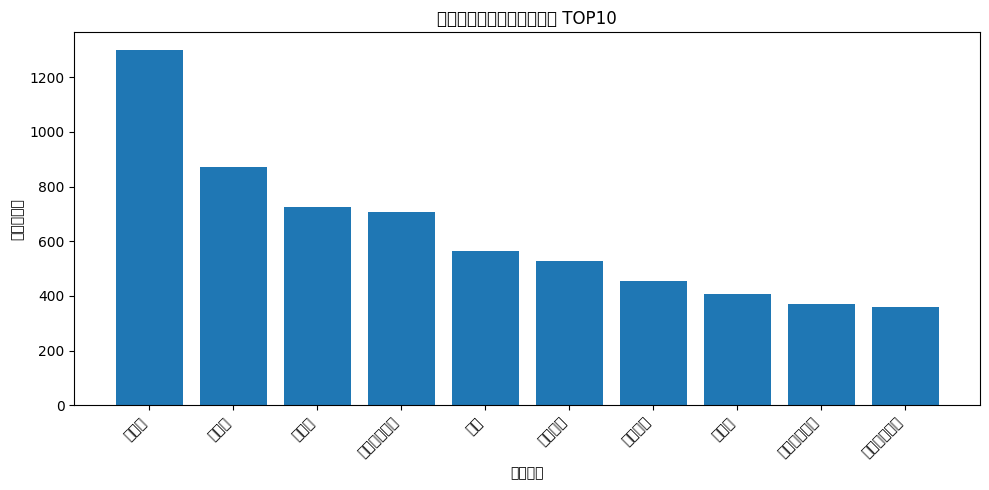

In [3]:
top_cities = city_counts.most_common(10)
plt.figure(figsize=(10, 5))
plt.bar([x[0] for x in top_cities], [x[1] for x in top_cities])
plt.title("自転車盗の市区町村別件数 TOP10")
plt.xlabel("市区町村")
plt.ylabel("件数（件）")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 3. 発生時刻の分析
時刻が「不明」の記録は時間別グラフから除き、除外件数も確認します。

/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 30330 (\N{CJK UNIFIED IDEOGRAPH-767A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 26178 (\N{CJK UNIFIED IDEOGRAPH-6642}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 20214 (\N{CJK UNIFIED IDEOGRAPH-4EF6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/669194183.py:23: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing fro

時刻不明: 103 件
件数が多い時間 TOP5
07時台: 901件
18時台: 879件
17時台: 877件
08時台: 706件
16時台: 697件


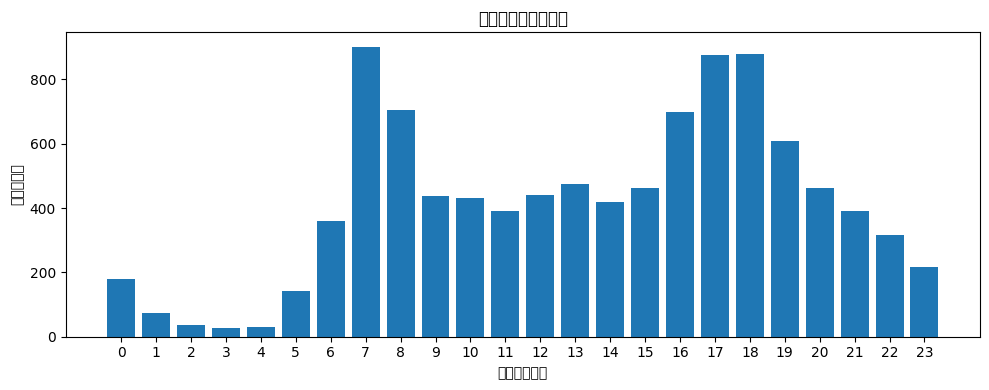

In [4]:
hour_counts = Counter()
unknown_hour = 0
for row in incidents:
    hour = row["発生時（始期）"]
    if hour.isdigit() and 0 <= int(hour) <= 23:
        hour_counts[int(hour)] += 1
    else:
        unknown_hour += 1

print("時刻不明:", unknown_hour, "件")
print("件数が多い時間 TOP5")
for hour, count in hour_counts.most_common(5):
    print(f"{hour:02d}時台: {count}件")

hours = list(range(24))
hour_values = [hour_counts[h] for h in hours]
plt.figure(figsize=(10, 4))
plt.bar(hours, hour_values)
plt.title("自転車盗の発生時刻")
plt.xlabel("発生時（時）")
plt.ylabel("件数（件）")
plt.xticks(hours)
plt.tight_layout()
plt.show()

## 4. 施錠状況の比較
施錠の有無ごとの記録件数と割合を比べます。ここから施錠による因果関係や防犯効果を直接証明できるわけではありません。

施錠せず: 6879件（68.4%）
施錠した: 3175件（31.6%）


/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 26045 (\N{CJK UNIFIED IDEOGRAPH-65BD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 37664 (\N{CJK UNIFIED IDEOGRAPH-9320}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 12379 (\N{HIRAGANA LETTER SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 12378 (\N{HIRAGANA LETTER ZU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 12375 (\N{HIRAGANA LETTER SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 12383 (\N{HIRAGANA LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/247977485.py:17: UserWarning: Glyph 38306 (\N{CJK UNIFIED IDEOGRAPH-95A2}) missing from font(s) DejaVu Sans.
  plt.tigh

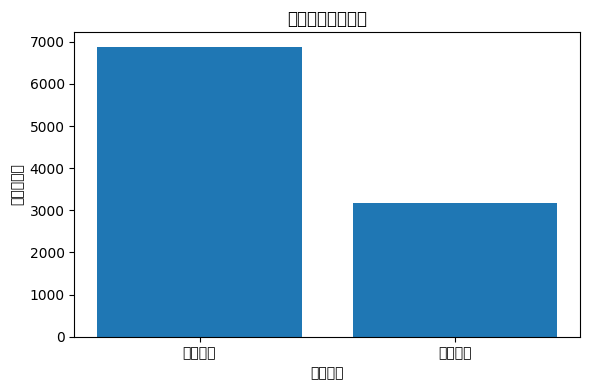

In [5]:
lock_counts = Counter()
for row in incidents:
    lock_counts[row["施錠関係"]] += 1

total = len(incidents)
for label in ["施錠せず", "施錠した"]:
    count = lock_counts[label]
    print(f"{label}: {count}件（{count / total * 100:.1f}%）")

plt.figure(figsize=(6, 4))
labels = ["施錠せず", "施錠した"]
values = [lock_counts[x] for x in labels]
plt.bar(labels, values)
plt.title("施錠状況別の件数")
plt.xlabel("施錠関係")
plt.ylabel("件数（件）")
plt.tight_layout()
plt.show()

## 5. 大学生の被害状況
被害者の職業が「大学生」の記録だけを取り出し、施錠状況・場所・時間帯を確認します。

In [6]:
university_rows = []
for row in incidents:
    if row["被害者の職業"] == "大学生":
        university_rows.append(row)

print("大学生の記録:", len(university_rows), "件")
uni_lock = Counter()
uni_place = Counter()
uni_hour = Counter()
for row in university_rows:
    uni_lock[row["施錠関係"]] += 1
    uni_place[row["発生場所"]] += 1
    hour = row["発生時（始期）"]
    if hour.isdigit() and 0 <= int(hour) <= 23:
        uni_hour[int(hour)] += 1

print("\n大学生の施錠状況")
for label, count in uni_lock.most_common():
    print(f"{label}: {count}件（{count / len(university_rows) * 100:.1f}%）")

print("\n大学生の発生場所 TOP5")
for place, count in uni_place.most_common(5):
    print(f"{place}: {count}件")

print("\n大学生の発生時刻 TOP5")
for hour, count in uni_hour.most_common(5):
    print(f"{hour:02d}時台: {count}件")

大学生の記録: 1594 件

大学生の施錠状況
施錠せず: 1084件（68.0%）
施錠した: 510件（32.0%）

大学生の発生場所 TOP5
駐車（輪）場: 591件
その他: 548件
その他の住宅（３階建て以下共同住宅等）: 212件
４階建て以上共同住宅: 117件
道路上: 81件

大学生の発生時刻 TOP5
17時台: 150件
08時台: 112件
16時台: 111件
18時台: 105件
09時台: 104件


## 6. 大学生の発生場所をグラフで見る

/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 39376 (\N{CJK UNIFIED IDEOGRAPH-99D0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 36650 (\N{CJK UNIFIED IDEOGRAPH-8F2A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 22580 (\N{CJK UNIFIED IDEOGRAPH-5834}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_485/1523603948.py:8: UserWarning: Glyph 12381 (\N{HIRAGANA LETTER SO}) missing from font(s

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22580 (\N{CJK UNIFIED IDEOGRAPH-5834}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25152 (\N{CJK UNIFIED IDEOGRAPH-6240}) missing from font(s) DejaVu Sans.
  fig.canvas.print

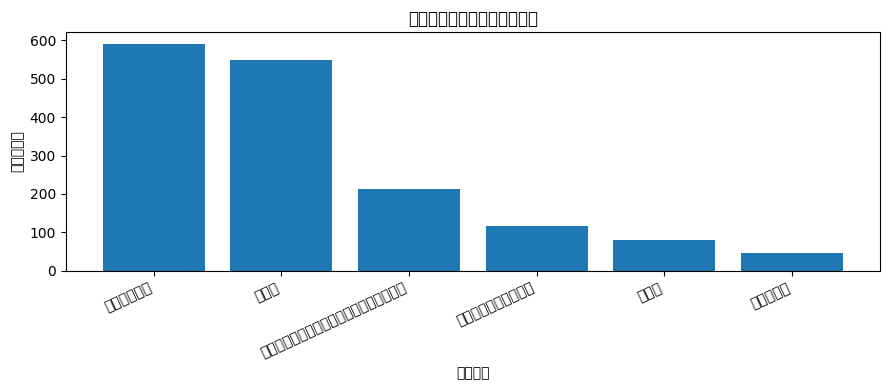

In [7]:
uni_places = uni_place.most_common()
plt.figure(figsize=(9, 4))
plt.bar([x[0] for x in uni_places], [x[1] for x in uni_places])
plt.title("大学生の自転車盗：発生場所")
plt.xlabel("発生場所")
plt.ylabel("件数（件）")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. 分析から分かったこと

今回の集計では、次の点が確認できます。

- 市区町村別では、記録件数が多い地域と少ない地域があります。ただし、件数だけで地域の安全・危険を決めることはできません。
- 全体では「施錠せず」の記録が多く、施錠状況は防犯を考えるうえで注目したい項目です。
- 大学生の記録だけに絞ると、大学生が被害に遭った場所や時間帯の傾向を確認できます。

下のセルでは、実際の集計値を使って発見を数値で表示します。

In [8]:
print(f"全体の施錠せずの割合: {lock_counts['施錠せず'] / total * 100:.1f}%")
print(f"全体の施錠した割合: {lock_counts['施錠した'] / total * 100:.1f}%")
print(f"大学生の記録: {len(university_rows)}件（全体の{len(university_rows) / total * 100:.1f}%）")
print(f"大学生の施錠せず: {uni_lock['施錠せず']}件（大学生記録の{uni_lock['施錠せず'] / len(university_rows) * 100:.1f}%）")
print(f"最多の市区町村: {city_counts.most_common(1)[0][0]}（{city_counts.most_common(1)[0][1]}件）")
print(f"最多の時間帯: {hour_counts.most_common(1)[0][0]:02d}時台（{hour_counts.most_common(1)[0][1]}件）")

全体の施錠せずの割合: 68.4%
全体の施錠した割合: 31.6%
大学生の記録: 1594件（全体の15.9%）
大学生の施錠せず: 1084件（大学生記録の68.0%）
最多の市区町村: 船橋市（1299件）
最多の時間帯: 07時台（901件）


## 8. 防犯対策の提案
今回の分析では、「鍵をかけていなかったせいで盗まれた」という記録がかなり多く見られました。この結果から、私たちは3つの提案をします。
　1つ目は、大学や駅の駐輪場で「短時間でも絶対に鍵をかけよう！」と目立つ場所に掲示して呼びかけることです。
　2つ目は、備え付けの鍵だけでなく、ワイヤー錠で固定物とつなぐ「二重ロック」を広めることです。
　3つ目は、大学生の被害が集中していた場所や時間帯のデータをもとに、掲示を出す場所や見回りを強化する時間帯を見直すこ　　　　　　とです。


*確認したこと
 データの総数は10,054件で、読み込み漏れがないか最初に確認しました。
 地域別や時間帯別などのグラフを作る際は、数字のズレが起きないよう元の件数と照らし合わせています。
 時間が不明だったデータは、時間帯別のグラフから分けて集計しました。

*分析の限界
 発生年に2019〜2025年や不明分が混ざっているので、2025年だけの傾向と言い切ることはできませんでした。
 人口や自転車の台数データがないため、地域ごとの「被害率」を出すところまでは踏み込めませんでした。
 鍵あり・なし.の情報だけだと、鍵の種類や駐輪時間までは見えないため、鍵の防犯効果を直接比べることは難しかったです。
 緯度や経度のデータがないので、地図上に正確な発生場所をマッピングすることはできませんでした。

*AI利用記録
 何から始めていいかわからず、AIを使って、分析の進め方やコードの一部、説明文の整理を補助してもらいました。実際のCSVを読み込み、件数やグラフを実行して確認することを前提に作成しています。チームでコードを変更・実行し、内容を説明できるように確認してください。

**担当**
 芳賀慶次.今井恭瑳：分析テーマ・防犯提案
